# Experimento 6 — Regularizar melhora a previsão?

**Hipótese:** encolher coeficientes melhora o RMSE fora da amostra. Com poucos atributos, o ganho pode ser pequeno ou inexistente.

Comparamos regressão comum, Ridge e Bayesian Ridge com os mesmos seis atributos do notebook 06. Ridge ajuda a distinguir um ganho de regularização de uma vantagem do procedimento bayesiano.

### Bayesian Ridge

Usa um modelo gaussiano para o ruído e um prior gaussiano que favorece coeficientes próximos de zero. Estima as precisões do ruído (`alpha_`) e dos coeficientes (`lambda_`) no treino: é Bayes empírico, sem MCMC. O intercepto não é penalizado.

`Ridge.alpha` é a penalização; no Bayesian Ridge, a razão `lambda_ / alpha_` permite comparar a penalização efetiva na mesma escala. Cortar previsões em [0, 5] não limita a distribuição gaussiana. Avaliamos previsões pontuais, não a calibração de intervalos.

[Referência: BayesianRidge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.BayesianRidge.html).

### O que este experimento traz de novo

| | |
|---|---|

| **Ponto de partida** | Regressão com os seis atributos do experimento 4 (RMSE 0,6250). |
| **O que muda** | Os coeficientes passam a ser **penalizados**. Os atributos são os mesmos. |
| **Modelos** | **Ridge** minimiza $\sum(y-\hat y)^2+\alpha\sum b_j^2$, com os atributos padronizados: quanto maior $\alpha$, mais os coeficientes são puxados para zero. **Bayesian Ridge** chega a uma penalização parecida estimando, no treino, a variância do ruído e a dos coeficientes. |
| **Por que esta mudança** | A regularização troca um pouco de viés por menos **variância**. Ela ajuda quando o modelo tem muitos parâmetros ou atributos correlacionados, como afinidade e afinidade². O experimento responde se a regressão de referência sofre de variância. |
| **Como ler o resultado** | Se a regressão já tiver gap $E_{CV} - E_{in}$ pequeno, a penalização tende a não ajudar: o erro restante seria de viés, não de variância. |

## 1. Configuração proposta

| Procedimento | Configuração |
|---|---|
| Todos | Intercepto e `StandardScaler` dentro do pipeline |
| Regressão comum | Sem penalização ou busca |
| Ridge | `alpha`: 0,01; 0,1; 1; 10; 100; 1000 |
| Seleção Ridge | 3 dobras internas, semente 2026, RMSE com corte |
| Bayesian Ridge | `alpha_1`, `alpha_2`, `lambda_1`, `lambda_2`: 1e-6 |
| Bayesian Ridge | `max_iter=1000`, `tol=1e-6`; inicialização automática |

Os priors são fixos, sem busca. São 450 ajustes internos de Ridge e 75 ajustes externos. Registre escolhas na borda da grade e ajustes que atinjam o limite de iterações.

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições para os modelos, apenas `train.csv`, previsões cortadas em [0, 5].

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. Só os gráficos usam a média dessas previsões. As partições compartilham treino: desvios e vitórias são descritivos, não testes de significância. As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
N_BINS = 8  # Somente visualização; não modifica os modelos.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
df = pd.read_csv(ROOT / 'data' / 'train.csv')
genres = ['action', 'comedy', 'drama']
assert set(df['genre'].unique()).issubset(genres)
required = ['user_avg_stars', 'movie_avg_stars', 'stars'] + ['share_' + g for g in genres]
assert not df[required].isna().any().any()
df['affinity'] = [row['share_' + row['genre']] for _, row in df.iterrows()]
assert df['affinity'].between(0, 1).all()
y = df['stars'].to_numpy(dtype=float)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
display(df[['genre', 'share_action', 'share_comedy', 'share_drama', 'affinity']].head())
print(f'{len(df)} linhas; {N_SPLITS} folds × {N_REPEATS} repetições; semente {SEED}; corte: {CLIP}')
df['affinity2'] = df['affinity'] ** 2

# Ação é a referência; categorias conhecidas não são aprendidas no conjunto.
df['genre_comedy'] = df['genre'].eq('comedy').astype(float)
df['genre_drama'] = df['genre'].eq('drama').astype(float)
BASE_FEATURES = ['user_avg_stars', 'movie_avg_stars', 'affinity', 'affinity2']
GENRE_FEATURES = BASE_FEATURES + ['genre_comedy', 'genre_drama']

FEATURES = GENRE_FEATURES
X = df[FEATURES].to_numpy(dtype=float)
assert np.isfinite(X).all() and np.isfinite(y).all()
assert ((y >= 0) & (y <= 5)).all()


,genre,share_action,share_comedy,share_drama,affinity
0,drama,0.315,0.501,0.184,0.184
1,action,0.180,0.151,0.669,0.180
2,action,0.701,0.258,0.041,0.701
3,action,0.700,0.204,0.096,0.700
4,action,0.621,0.257,0.122,0.621


4000 linhas; 5 folds × 5 repetições; semente 2026; corte: True


In [2]:
import sklearn
from sklearn.base import clone
from sklearn.linear_model import Ridge, BayesianRidge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import make_scorer

INNER_SPLITS = 3
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
BAYES_PARAMS = dict(alpha_1=1e-6, alpha_2=1e-6,
                    lambda_1=1e-6, lambda_2=1e-6,
                    max_iter=1000, tol=1e-6,
                    alpha_init=None, lambda_init=None,
                    fit_intercept=True, compute_score=True)

def pipeline(estimator):
    return Pipeline([('scale', StandardScaler()), ('model', estimator)])

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

def selection_rmse(actual, predicted):
    return rmse(actual, np.clip(predicted, 0, 5) if CLIP else predicted)

def predict_checked(model, values):
    # Equação explícita para os três modelos lineares, na escala do pipeline.
    scaled = model.named_steps['scale'].transform(values)
    fitted = model.named_steps['model']
    pred = np.sum(scaled * fitted.coef_, axis=1) + fitted.intercept_
    assert np.isfinite(pred).all()
    return np.clip(pred, 0, 5) if CLIP else pred

def scorer(estimator, values, actual):
    # Mesmo RMSE e corte; usa a equação explícita também nas dobras internas.
    return -rmse(actual, predict_checked(estimator, values))
candidates = {
    'Regressão comum': pipeline(LinearRegression()),
    'Ridge': pipeline(Ridge()),
    'Bayesian Ridge': pipeline(BayesianRidge(**BAYES_PARAMS)),
}
print('scikit-learn:', sklearn.__version__)
print('Atributos:', FEATURES)
print('Grade Ridge:', RIDGE_ALPHAS)
print('Configuração bayesiana:', BAYES_PARAMS)


scikit-learn: 1.6.1
Atributos: ['user_avg_stars', 'movie_avg_stars', 'affinity', 'affinity2', 'genre_comedy', 'genre_drama']
Grade Ridge: [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
Configuração bayesiana: {'alpha_1': 1e-06, 'alpha_2': 1e-06, 'lambda_1': 1e-06, 'lambda_2': 1e-06, 'max_iter': 1000, 'tol': 1e-06, 'alpha_init': None, 'lambda_init': None, 'fit_intercept': True, 'compute_score': True}


## 2. Ajuste nas mesmas partições

A padronização é refeita em cada treino, inclusive na busca interna de Ridge. Bayesian Ridge estima as precisões apenas no treino externo.

In [3]:
folds = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                           random_state=SEED).split(X))
predictions_by_repeat = {name: np.full((N_REPEATS, len(y)), np.nan) for name in candidates}
coverage = np.zeros((N_REPEATS, len(y)), dtype=int)
rows, selections, coefficients = [], [], []
for partition, (train, valid) in enumerate(folds):
    repeat = partition // N_SPLITS
    assert not np.intersect1d(train, valid).size
    coverage[repeat, valid] += 1
    for name, template in candidates.items():
        model = clone(template)
        if name == 'Ridge':
            search = GridSearchCV(
                model, {'model__alpha': RIDGE_ALPHAS}, scoring=scorer,
                cv=KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED),
                n_jobs=1, error_score='raise', refit=True)
            search.fit(X[train], y[train])
            model = search.best_estimator_
            selections.append({'particao': partition + 1, 'modelo': name,
                               'penalização efetiva': search.best_params_['model__alpha'],
                               'RMSE interno selecionado': -search.best_score_})
        else:
            model.fit(X[train], y[train])
        fitted = model.named_steps['model']
        if name == 'Bayesian Ridge':
            selections.append({'particao': partition + 1, 'modelo': name,
                               'precisão ruído': fitted.alpha_,
                               'precisão coeficientes': fitted.lambda_,
                               'penalização efetiva': fitted.lambda_ / fitted.alpha_,
                               'iterações': fitted.n_iter_,
                               'atingiu limite': fitted.n_iter_ >= BAYES_PARAMS['max_iter']})
        pred = predict_checked(model, X[valid])
        predictions_by_repeat[name][repeat, valid] = pred
        rows.append({'modelo': name, 'particao': partition + 1,
                     'E_CV': rmse(y[valid], pred),
                     'E_in': rmse(y[train], predict_checked(model, X[train]))})
        coefficients.extend({'modelo': name, 'particao': partition + 1,
                             'atributo': feature, 'coeficiente padronizado': value}
                            for feature, value in zip(FEATURES, fitted.coef_))
assert (coverage == 1).all()
assert all(np.isfinite(values).all() for values in predictions_by_repeat.values())
by_fold = pd.DataFrame(rows)
oof = pd.DataFrame({name: values.mean(axis=0) for name, values in predictions_by_repeat.items()})
summary = by_fold.groupby('modelo', sort=False).agg(
    E_CV=('E_CV', 'mean'),
    desvio_E_CV=('E_CV', 'std'),
    E_in=('E_in', 'mean'))
summary.insert(0, 'RMSE OOF repetido',
               [rmse(y, predictions_by_repeat[name]) for name in summary.index])
display(summary.round(6))


,RMSE OOF repetido,E_CV,desvio_E_CV,E_in
modelo,,,,
Regressão comum,0.625036,0.624868,0.014793,0.623377
Ridge,0.625036,0.624868,0.014792,0.623378
Bayesian Ridge,0.625074,0.624907,0.014746,0.623414


## 3. Comparação pareada

Diferenças negativas favorecem o candidato. Compare a magnitude e a consistência do ganho, não apenas o sinal.

In [4]:
paired = by_fold.pivot(index='particao', columns='modelo', values='E_CV')
comparisons = [('Ridge', 'Regressão comum'), ('Bayesian Ridge', 'Regressão comum'),
               ('Bayesian Ridge', 'Ridge')]
differences = pd.DataFrame({f'{a} − {b}': paired[a] - paired[b] for a, b in comparisons})
display(differences.round(6))
display(pd.DataFrame({'diferença média': differences.mean(),
                      'desvio descritivo': differences.std(),
                      'partições com melhora': (differences < 0).sum()}))
per_repeat = pd.DataFrame({name: [rmse(y, pred) for pred in values]
                          for name, values in predictions_by_repeat.items()},
                         index=pd.Index(range(1, N_REPEATS + 1), name='repetição'))
for a, b in comparisons:
    per_repeat[f'{a} − {b}'] = per_repeat[a] - per_repeat[b]
display(per_repeat.round(6))
display(pd.DataFrame(selections))
limit_hits = [s['particao'] for s in selections
              if s['modelo'] == 'Bayesian Ridge' and s['atingiu limite']]
print('Partições Bayesian Ridge que atingiram o limite de iterações:', limit_hits)
if limit_hits:
    print('Investigar convergência antes de interpretar o desempenho.')


,Ridge − Regressão comum,Bayesian Ridge − Regressão comum,Bayesian Ridge − Ridge
particao,,,
1,-0.000001,-0.000028,-0.000027
2,0.000002,0.000103,0.000101
3,0.000000,0.000020,0.000019
4,0.000002,0.000141,0.000139
5,-0.000001,-0.000040,-0.000039
6,-0.000001,-0.000038,-0.000038
7,0.000003,0.000189,0.000186
8,0.000000,0.000031,0.000030
9,0.000002,0.000151,0.000148


,diferença média,desvio descritivo,partições com melhora
Ridge − Regressão comum,5.235047e-07,0.000002,10
Bayesian Ridge − Regressão comum,3.927760e-05,0.000118,10
Bayesian Ridge − Ridge,3.875409e-05,0.000116,10


,Regressão comum,Ridge,Bayesian Ridge,Ridge − Regressão comum,Bayesian Ridge − Regressão comum,Bayesian Ridge − Ridge
repetição,,,,,,
1,0.624681,0.624682,0.624721,0.000001,0.000040,0.000039
2,0.624874,0.624874,0.624915,0.000001,0.000041,0.000040
3,0.625119,0.625119,0.625162,0.000001,0.000043,0.000042
4,0.624970,0.624971,0.625006,0.000000,0.000035,0.000035
5,0.625535,0.625536,0.625568,0.000000,0.000032,0.000032


,particao,modelo,penalização efetiva,RMSE interno selecionado,precisão ruído,precisão coeficientes,iterações,atingiu limite
0,1,Ridge,0.010000,0.624288,NaN,NaN,NaN,NaN
1,1,Bayesian Ridge,0.568378,NaN,2.473678,1.405983,5.0,False
2,2,Ridge,0.010000,0.626168,NaN,NaN,NaN,NaN
3,2,Bayesian Ridge,0.610225,NaN,2.460962,1.501740,5.0,False
4,3,Ridge,0.010000,0.626639,NaN,NaN,NaN,NaN
5,3,Bayesian Ridge,0.590211,NaN,2.447485,1.444532,5.0,False
6,4,Ridge,0.010000,0.621487,NaN,NaN,NaN,NaN
7,4,Bayesian Ridge,0.595505,NaN,2.505912,1.492282,5.0,False
8,5,Ridge,0.010000,0.626621,NaN,NaN,NaN,NaN
9,5,Bayesian Ridge,0.573368,NaN,2.458656,1.409713,5.0,False


Partições Bayesian Ridge que atingiram o limite de iterações: []


## 4. Coeficientes e resíduos

Os coeficientes estão na escala padronizada de cada treino. Seu desvio entre partições não é um desvio posterior. Com atributos correlacionados, coeficientes podem variar sem mudar muito as previsões.

As métricas por gênero usam todos os erros OOF; os gráficos usam previsões médias. Regularização não acrescenta novas formas funcionais.

media  desvio_particoes
modelo          atributo                                  
Regressão comum user_avg_stars   0.55566           0.00687
                movie_avg_stars  0.59972           0.00798
                affinity         1.53892           0.03227
                affinity2       -1.07232           0.03061
                genre_comedy    -0.02500           0.00544
                genre_drama      0.05895           0.00604
Ridge           user_avg_stars   0.55565           0.00687
                movie_avg_stars  0.59971           0.00798
                affinity         1.53873           0.03226
                affinity2       -1.07213           0.03061
                genre_comedy    -0.02500           0.00545
                genre_drama      0.05894           0.00604
Bayesian Ridge  user_avg_stars   0.55499           0.00687
                movie_avg_stars  0.59961           0.00796
                affinity         1.52809           0.03250
                affinity2       -1.06134           0.03084
                genre_comedy    -0.02466           0.00545
                genre_drama      0.05861           0.00604

,modelo,gênero,n,resíduo médio,RMSE OOF repetido
0,Regressão comum,action,1462,0.03193,0.62123
1,Regressão comum,comedy,1254,0.00856,0.63820
2,Regressão comum,drama,1284,0.02414,0.61630
3,Ridge,action,1462,0.03193,0.62123
4,Ridge,comedy,1254,0.00856,0.63821
5,Ridge,drama,1284,0.02414,0.61630
6,Bayesian Ridge,action,1462,0.03195,0.62113
7,Bayesian Ridge,comedy,1254,0.00850,0.63846
8,Bayesian Ridge,drama,1284,0.02410,0.61627


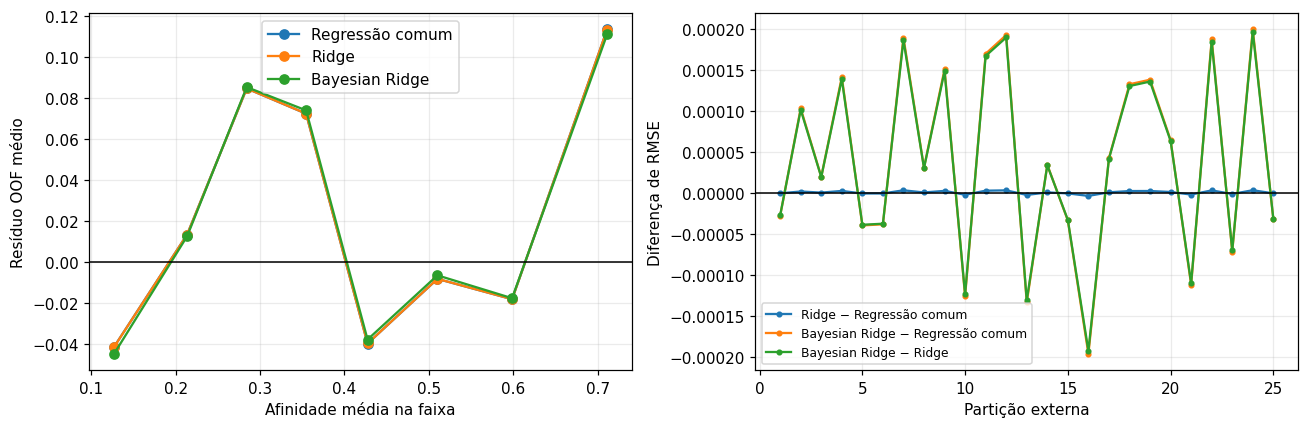

In [5]:
display(pd.DataFrame(coefficients).groupby(['modelo', 'atributo'], sort=False).agg(
    media=('coeficiente padronizado', 'mean'),
    desvio_particoes=('coeficiente padronizado', 'std')).round(5))
residuals = oof.apply(lambda pred: y - pred)
rows_genre = []
for name in candidates:
    for genre in genres:
        mask = df['genre'].eq(genre).to_numpy()
        rows_genre.append({'modelo': name, 'gênero': genre, 'n': int(mask.sum()),
                          'resíduo médio': residuals.loc[mask, name].mean(),
                          'RMSE OOF repetido': rmse(y[mask], predictions_by_repeat[name][:, mask])})
display(pd.DataFrame(rows_genre).round(5))
bins = pd.qcut(df['affinity'], N_BINS, duplicates='drop')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in candidates:
    table = pd.DataFrame({'affinity': df['affinity'], 'residuo': residuals[name]}).groupby(
        bins, observed=True).agg(x=('affinity', 'mean'), residuo=('residuo', 'mean'))
    axes[0].plot(table['x'], table['residuo'], 'o-', label=name)
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set(xlabel='Afinidade média na faixa', ylabel='Resíduo OOF médio')
axes[0].legend()
for label in differences:
    axes[1].plot(differences.index, differences[label], '.-', label=label)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(xlabel='Partição externa', ylabel='Diferença de RMSE')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 5. Conclusão do grupo

- Ridge e Bayesian Ridge melhoram o RMSE de forma relevante? Há diferença entre eles?
- Como mudam a distância entre $E_{in}$ e $E_{CV}$ e a estabilidade dos coeficientes?
- Há escolhas na borda da grade, limite de iterações ou padrões persistentes nos resíduos?

**Respostas, com base na execução registrada abaixo.** Não: regressão comum, Ridge e Bayesian Ridge ficaram em 0,625036, 0,625036 e 0,625074. Ridge escolheu o menor `alpha` da grade nas 25 partições, e a distância entre $E_{in}$ e $E_{CV}$ já era pequena (≈ 0,0015). A regressão não sofre de variância; o erro restante é de viés, e penalizar não o reduz.

Resultados semelhantes também são informativos; diferenças na última casa decimal não bastam para escolher um vencedor. Este experimento não testa a confiabilidade das médias por contagem.

## Registro reproduzível desta execução

Salvamos previsões OOF por repetição, erros por partição, configurações selecionadas, versões e identificadores dos dados e do código em `results/rodada_atual`. Esses arquivos não se misturam aos resultados históricos.

In [6]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.current_results import save_run
save_run(ROOT, '08_hipotese_regularizacao_bayesiana', df, y, predictions_by_repeat, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP, globals().get('selections'))

Resultados verificados e salvos em /Users/mrm/Documents/Disciplinas/Apredizagem Estatística/movie-rating-prediction/results/rodada_atual/08_hipotese_regularizacao_bayesiana.json


## Leitura da execução de 15 de novembro de 2026

O RMSE OOF repetido foi **0,625036** na regressão comum, **0,625036** no Ridge e **0,625074** no Bayesian Ridge. As diferenças são desprezíveis em termos práticos; esta execução não sustenta ganho preditivo material da regularização.

Ridge escolheu **alpha = 0,01**, o menor valor da grade, nas 25 partições. A regressão sem penalização já está presente como referência, portanto não há motivo para ampliar automaticamente a grade para valores ainda menores. Bayesian Ridge não atingiu o limite de iterações. Isso não descarta outros modelos bayesianos: confiabilidade das médias por contagem e intervalos preditivos não foram testados aqui.

A referência usa poucos atributos e já apresenta pequena distância entre $E_{in}$ e $E_{CV}$. O próximo passo é sintetizar a comparação com boosting e examinar os erros restantes, e não aumentar a penalização sem evidência.

Esta leitura se refere à execução salva nesta rodada. Desvios e contagens são descritivos, não testes independentes. Revisar os números e o texto se dados, código ou configuração mudarem. As questões do grupo permanecem abertas à discussão.